# What risk does a deterministic plan carry under changing geology?

**Question:** How does a plan optimized on one block-value model score across spatially correlated value realisations?

**Level:** 1 — Fundamentals

**Prerequisites:** None; start here.

**Reading time:** 16 minutes

## Objectives

This lesson separates building a deterministic schedule, generating uncertain block values, and scoring a fixed plan under those values. You construct a small CPIT case with PhaseFlow, solve it with OreBlocks, perturb values with a spatial field, and compute a distribution for the same period assignment. The spread describes risk conditional on an explicitly synthetic generator. It is not a stochastic optimization result, conditional simulation, or confidence interval for a real deposit. Explain why the mean-model forecast may differ from average re-scored value and name the assumptions behind that difference. The 48-block case makes each stage inspectable; it does not represent a mine's scale or economics.

## Setup

From the repository root, install the pinned environment once with `python -m pip install -r notebooks/requirements.txt`. This notebook does not install packages; the import cell reports active versions. `oreblocks==0.6.3`.

```bash
python -m pip install -r notebooks/requirements.txt
```

In [1]:
# Import the documented pipeline and methods; report active versions.
import importlib.metadata as metadata
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.3
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Data

PhaseFlow's MIT-licensed teaching pipeline builds a declared synthetic vein: dimensions 4×4×3, seed 31, four periods, and an 8% discount rate. It constructs values, resource coefficients, coordinates, and precedence. No MineLib values are modified. OreBlocks 0.6.3 supplies scheduling and uncertainty methods. The value ensemble is a seeded, spatially correlated lognormal stress generator, not observed geology or a conditionally simulated block model. Its 24 equally weighted draws are reproducible below. Keep this provenance attached to every interpretation: synthetic draws show behavior under stated assumptions, not how likely those assumptions are at a real operation.

## Method

For a fixed period assignment τ and value realisation r, the discounted score is V(τ,r) = Σ[b:τ_b≥0] (1+ρ)^(-τ_b) v_(b,r). The schedule stays fixed while block values change. This is an exact re-score of that plan under those values; it does not establish that the plan remains optimal. First, construct and validate the input; next, compute one deterministic reference schedule. Then smooth a white random field over neighboring blocks and apply it multiplicatively in log space. Finally, `evaluate_across` scores the unchanged assignment against every draw. Tonnage and capacity do not change, so the calculation isolates value exposure. No re-optimization occurs, so this is not a stochastic program.

### Step 1: build the declared input

The case declaration exposes dimensions, seed, horizon, discount rate, and resource fractions. `build_instance` is the named PhaseFlow pipeline entry point; its report indicates whether the generated object meets the instance contract. The small geometry makes every input inspectable and keeps the method run quick. Its resulting currency-like values are teaching outputs, not a business case. Changing the seed creates another synthetic orebody, while changing the scenario changes the scheduling question. Preserve those choices separately when adapting the example.

In [2]:
# Declare a reproducible case and construct its validated instance.
case = Case(
    id='uncertainty-vein-4x4x3', category='teaching',
    title_en='Small synthetic vein', title_es='Veta sintetica pequena',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(
        periods=4, discount_rate=0.08, capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing'),
    ),
)
instance = build_instance(case)
print('contract accepted:', instance.report.ok, '| blocks:', instance.n_blocks)

contract accepted: True | blocks: 48


### Step 2: solve the deterministic reference

The Expected method assigns blocks using generated base values and declared resource and precedence constraints. Keep the full result rather than only its NPV: its period assignment is the object whose exposure we study. The reported forecast and upper bound belong to this deterministic CPIT instance. Neither quantity bounds a random ensemble unless the model and proof explicitly include those value realisations. This prevents a deterministic certificate from being mislabeled as a risk guarantee.

In [3]:
# Solve once on the deterministic base values; retain the period assignment.
schedule, _ = ob.solve_cpit(instance.cpit, instance.precedence, method='expected', local_search=False)
print(schedule.method, '| NPV:', round(schedule.npv, 2), '| blocks:', schedule.mined_blocks)

toposort:expected[r1] | NPV: 179191.57 | blocks: 16


### Step 3: create correlated value draws

`perturb_values` creates 24 draws with fixed seed, sigma 0.25, and a two-block correlation scale. Smoothing matters because independent errors can cancel across a pushback and understate variation. The implementation recenters and rescales each finite field before applying a mean-corrected multiplicative transform. This transparent stress model is not a fitted variogram. It changes values only; tonnage, capacity, discounting, and schedule remain untouched. A real study should replace this step with documented conditional simulations and preserve their provenance and scenario weights.

In [4]:
# Generate correlated value draws without changing tonnage or capacity.
ensemble = ob.perturb_values(
    instance.cpit.value, instance.x, instance.y, instance.level,
    n=24, sigma=0.25, correlation_blocks=2.0, seed=19,
)
print('draws:', ensemble.n_realisations, '| sigma:', ensemble.sigma)
print(ensemble.note)

draws: 24 | sigma: 0.25
SYNTHETIC geological uncertainty: a seeded lognormal multiplicative perturbation of the block values with a spatially correlated field, NOT a conditional simulation with drillhole data behind it.


### Step 4: score the fixed decision

`evaluate_across` discounts every mined block in its assigned period and computes one NPV per draw. The result exposes mean, lower-tail P10, upper-tail P90, and deterministic optimism, defined as base-model forecast minus ensemble mean. Positive optimism says the single-model forecast is higher in this experiment; negative values are possible. We intentionally omit per-realisation optima, so no value-of-perfect-information number is produced. Re-scoring candidate plans is not the same as finding the best schedule after geology is known.

In [5]:
# Re-score the unchanged schedule against each realisation.
risk = ob.evaluate_across(
    instance.cpit, ensemble, {schedule.method: schedule.period_of_block},
)
print('mean:', round(float(risk.expected[0]), 2))
print('P10:', round(float(risk.p10[0]), 2), '| P90:', round(float(risk.p90[0]), 2))

mean: 173035.23
P10: 129694.82 | P90: 226632.3


## Results

**Answer:** Across 24 synthetic draws, the fixed Expected plan averages 173035.23 value units (P10 129694.82, P90 226632.30). Its base-model forecast is 179191.57, an optimism of 6156.34 relative to the ensemble mean. These are stress-test outcomes, not calibrated deposit probabilities.

In [6]:
# Print the exact quantities used in the answer.
print(f'mean={risk.expected[0]:.2f}; P10={risk.p10[0]:.2f}; P90={risk.p90[0]:.2f}')
print(f'base={risk.mean_model_npv[0]:.2f}; optimism={risk.deterministic_optimism[0]:.2f}')

mean=173035.23; P10=129694.82; P90=226632.30
base=179191.57; optimism=6156.34


Plot the computed ensemble scores and compare them with the deterministic forecast. The value units come from this generated instance.

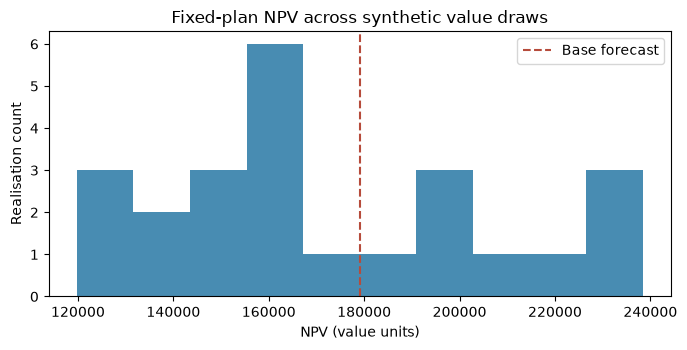

In [7]:
# Plot each computed scenario score and mark the base forecast.
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(risk.matrix[0], bins=10, color='#2878a5', alpha=0.85)
ax.axvline(risk.mean_model_npv[0], color='#b64b3b', linestyle='--', label='Base forecast')
ax.set(
    title='Fixed-plan NPV across synthetic value draws',
    xlabel='NPV (value units)', ylabel='Realisation count',
)
ax.legend()
fig.tight_layout()
plt.show()

### Figure 1

The histogram shows the fixed plan's NPV under each equally weighted synthetic draw. The dashed line is its score on the unperturbed model. Their relative positions reveal forecast optimism for this seed and generator. The tails are frequencies in a designed experiment, not calibrated probabilities for a mine. A narrow histogram would not prove low geological risk: this case has only 48 blocks and the perturbation kernel spans two blocks. The plot uses the same scores summarized in the output, so the interpretation can be checked against the calculated mean and P10.

## Summary

You constructed a deterministic plan and measured its exposure across a reproducible, spatially correlated synthetic ensemble. This teaches scenario analysis by separating schedule choice from re-scoring. For operational use, substitute documented conditional simulations, keep their weights, include uncertainty drivers that matter to the decision, and compare multiple candidate plans. To claim adaptation value, re-solve each draw or use a stochastic model. This output is an experiment on a tiny twin, not a forecast for MineLib or a production deposit.

## References

- PhaseFlow synthetic instance contract and builder: `data-pipeline/pipeline/io/schema.py`, `data-pipeline/pipeline/model/instances.py` (MIT).
- OreBlocks 0.6.3: `oreblocks.perturb_values` and `oreblocks.evaluate_across`.
- Blom, Pearce & Cote: https://arxiv.org/abs/2403.18213.
- Ramazan & Dimitrakopoulos: https://doi.org/10.1007/s11081-012-9186-2.
- Meagher, Dimitrakopoulos & Avis: https://doi.org/10.1134/S1062739114030132.